## 1. 데이터셋 준비하기

Auto Encoder: Encoder + Decoder
두 모델은 함께 학습되며 encoder가 중간 단계의 특성 표현을 생성하면 decoder는 이를 사용하여 입력 데이터를 재구성.
학습이 성공적으로 이루어지면 auto encoder는 입력 데이터의 핵심 특성을 추출하는 방법을 학습하게 됨. 
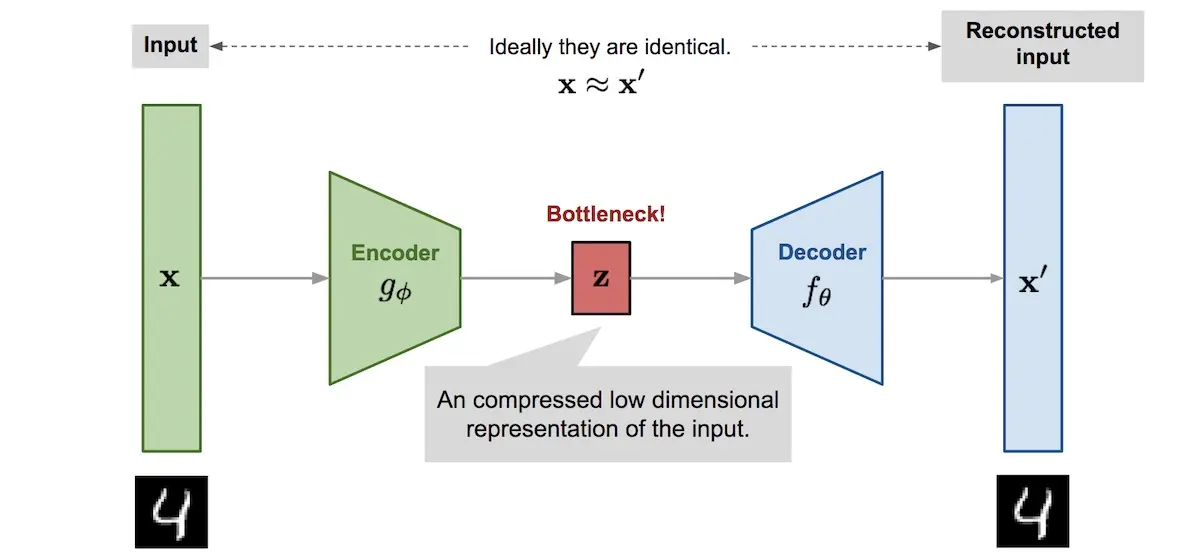

### 1. Preparing Dataset, MNIST
- 28 * 28, 60000/10000
- using library "datasets"

In [2]:
!pip -q install datasets genaibook

In [3]:
from datasets import load_dataset
mnist = load_dataset("mnist")
mnist

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

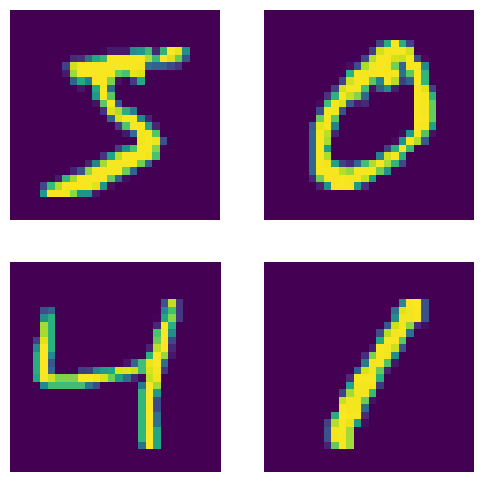

In [4]:
from genaibook.core import show_images
show_images(mnist["train"]["image"][:4])

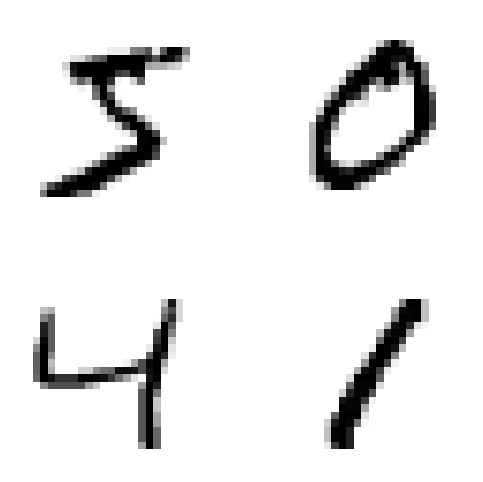

In [5]:
import matplotlib as mpl
mpl.rcParams["image.cmap"] = "gray_r"
show_images(mnist["train"]["image"][:4])

다음 예제에서는 이미지를 파이토치 텐서로 변환하고 학습 데이터셋을 섞는다. 
torchvision 라이브러리에서 입력 픽셀을 ToTensor()로 사용하여 파이토치 텐서로 변환한다. 이때 [0, 255] 범위의 값을 0에서 1로 변환하고 다른 조작은 하지 않음. 

In [6]:
from torchvision import transforms

def mnist_to_tensor(samples):
    t = transforms.ToTensor()
    samples["image"] = [t(image) for image in samples["image"]]
    return samples

mnist=mnist.with_transform(mnist_to_tensor)
mnist["train"]=mnist["train"].shuffle(seed=42)

데이터셋에서 이미지를 하나 확인하고 입력 픽셀이 0에서 1사이인지 확인해보자. 

0.0 1.0


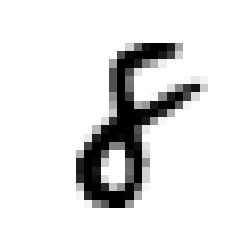

In [7]:
x = mnist["train"]["image"][0]
print(x.min().item(), x.max().item())
show_images([x])

다음 코드로 DataLoader를 만들어 학습 데이터를 준비한다. 
오토인코더를 학습하는 것은 Self-sueprvised Learing이므로 데이터셋의 image열을 활용하고 레이블은 무시한다(이후 결과 시각화 시 레이블 사용)
이 예제에서는 모든 이미지의 크기가 같으므로 모든 텐서의 형태도 같으며 Dataloader가 이를 함께 연결한다. 만약 입력크기가 다르면 패딩이나 잘라내기가 필요하다. 

In [8]:
from torch.utils.data import DataLoader

bs = 64
train_dataloader = DataLoader(mnist["train"]["image"], batch_size=bs)

## 2. Encoder 모델링

먼저 오토 인코더의 인코더 부분에 대한 모델을 학습해 본다. 이미지 데이터를 다루므로 이미지 특성을 효과적으로 추출하는 합성곱 층을 사용하는 것이 적합하다.
하지만 이외에도 선형 계층, 트랜스포머 블록, residual skip connection등 다양한 대안을 사용할 수 있다. 
pythae 라이브러리의 합성곱 오토 인코더 구현을 기반으로 간단한 합성곱 인코더를 사용해보자. 
이때 여러 개의 합성곱 층을 쌓을 예정이기 때문에 이를 생성하는 간단한 헬퍼 함수인 conv_block()을 작성한다. 이 함수는 2D 합성곱을 수행한 후 배치 정규화 계층과 비선형성을 추가한다. 
이번 예제에서는 ReLU를 사용한다. 
학습 중에는 배치 정규화가 현재 배치의 평균과 표준 편차를 사용하여 입력 데이터를 정규화한다. 이를 통해 데이터가 예측 가능한 범위 내에서 유지되며 대체로 더 부드럽고 빠른 학습으로 이어진다. 

In [9]:
from torch import nn

def conv_block(in_channels, out_channels, kernel_size=4, stride=2, padding=1):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
    )

인코더 구현은 합성곱 층의 시퀀스가 된다. 각 층은 점진적으로 이미지 해상도를 줄이면서 표현의 채널수를 1024까지 올린다. 
마지막으로 16차원 벡터 표현을 생성하기 위해 선형층을 추가한다. 

In [10]:
class Encoder(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.conv1 = conv_block(in_channels, 128)
        self.conv2 = conv_block(128, 256)
        self.conv3 = conv_block(256, 512)
        self.conv4 = conv_block(512, 1024)
        self.linear = nn.Linear(1024, 16)
    
    def forward(self, x):
        x = self.conv1(x) # (bs, 128, 14, 14)
        x = self.conv2(x) # (bs, 256, 7, 7)
        x = self.conv3(x) # (bs, 512, 4, 4)
        x = self.conv4(x) # (bs, 1024, 1, 1)
        x = self.linear(x.flatten(start_dim=1)) # (bs, 16)
        return x

In [11]:
mnist["train"]["image"][0].shape

torch.Size([1, 28, 28])

파이토치의 None 인덱싱을 사용하여 이미지를 선택하고 배치 안에 하나의 이미지로 넣어 새로운 차원을 만든다. 또한 인코더를 eval 모드로 설정해야 한다. 
이 모드는 모델을 학습이 아닌 추론 목적으로 설정한다. 이렇게 하지 않으면 마지막 BatchNorm2d 층이 [1, 1024, 1, 1] 형태의 텐서를 받게 되어 실패한다. 단일 샘플의 평균과 표준편차를 계산할 수 없기 때문이다. 

In [12]:
in_channels = 1
x=mnist["train"]["image"][0][None, :]
encoder = Encoder(in_channels).eval()

encoded = encoder(x)
encoded.shape

torch.Size([1, 16])

위 인코더가 잘 동작함을 알 수 있다. 
- 28 * 28 -> 16개의 벡터로 변환

In [13]:
encoded

tensor([[ 0.0254, -0.0247,  0.0041, -0.0192, -0.0264,  0.0208, -0.0219, -0.0213,
          0.0137,  0.0054,  0.0297, -0.0116, -0.0114,  0.0219,  0.0074, -0.0225]],
       grad_fn=<AddmmBackward0>)

64장의 이미지를 한꺼번에 처리할 수 있는지 살펴보자

In [14]:
batch = next(iter(train_dataloader))
encoded = Encoder(in_channels=1).eval()(batch)
batch.shape, encoded.shape

(torch.Size([64, 1, 28, 28]), torch.Size([64, 16]))

## 3. Decoder

디코더는 인코더로부터 얻은 latent representatin(16차원 벡터)으로 시작하여 원래 크기의 이미지 인코더로 변환한다. 
디코더는 인코더의 역순일 필요가 없으며, 인코더와 거의 대칭적인 신경망을 생성한다. 
transposed convolution을 적용하여 해상도를 점차 높으면서 채널 수를 점차 줄여 원하는 출력 해상도인 28 * 28에 도달하게 된다. 

https://github.com/aqeelanwar/conv_layers_animation

transposed convolution 앞에 선형 층을 추가하여 16_384(1024 * 4 * 4) 픽셀의 텐서를 생성
이 층은 4 * 4([1024, 4, 4])로 재구성되어 첫 번째 전치 합성곱의 입력이 됨
여기서부터 채널을 점차 줄이고 해상도를 높여 원본 이미지 형태에 도달하게 됨. 


In [15]:
def conv_transpose_block(in_channels, out_channels, kernel_size=3, stride=2, padding=1, output_padding=0, with_act=True):
    modules = [
        nn.ConvTranspose2d(
            in_channels, 
            out_channels,
            kernel_size=kernel_size, 
            stride=stride, 
            padding=padding, 
            output_padding=output_padding),
    ]
    
    if with_act:
        modules
        modules.append(nn.ReLU())
    return nn.Sequential(*modules)


class Decoder(nn.Module):
    def __init__(self, out_channels):
        super().__init__()
        self.linear = nn.Linear(16, 1024 * 4 * 4)
        self.t_conv1 = conv_transpose_block(1024, 512)
        self.t_conv2 = conv_transpose_block(512, 256, output_padding=1)
        self.t_conv3 = conv_transpose_block(256, out_channels, output_padding=1)

    def forward(self, x):
        bs = x.shape[0]
        x = self.linear(x)
        x = x.reshape((bs, 1024, 4, 4))
        x = self.t_conv1(x) # (bs, 512, 7, 7)
        x = self.t_conv2(x) # (bs, 256, 14, 14)
        x = self.t_conv3(x) # (bs, 1, 28, 28)
        return x
    

decoded_batch = Decoder(x.shape[0])(encoded)
decoded_batch.shape

torch.Size([64, 1, 28, 28])

## 4. 학습

지금까지 만든 인코더와 디코더는 아직 연결되지 않은 상태이며 무작위 가중치로 초기화되었다. 이제 두 요소가 동일한 잠재 표현을 이해할 수 있도록 함꼐 학습시켜야 한다. 
이제 이를 위해 인코더를 거쳐 디코더까지 입력 데이터를 순차적으로 통과시키는 AutoEncoder 모델을 생성한다. 출력에서 나온 디코딩된 이미지와 입력으로 제공한 원본 이미지 간의 차이를 최소화하도록 학습시킨다. 학습이 성공적으로 이루어지면 출력이미지가 입력과 유사해질 것이다. 

In [16]:
class AutoEncoder(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.encoder = Encoder(in_channels)
        self.decoder = Decoder(in_channels)
    
    def encode(self, x):
        return self.encoder(x)
    
    def decode(self, x):
        return self.decoder(x)

    def forward(self, x):
        return self.decode(self.encode(x))
    
model= AutoEncoder(1)

torchsummary 라이브러리를 사용해 모델의 요약정보를 출력할 수 있다. 이는 각 층의 변수 수와 출력 형태를 보여준다

In [17]:
import torchsummary

torchsummary.summary(model, input_size=(1, 28, 28),device="cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 128, 14, 14]           2,176
       BatchNorm2d-2          [-1, 128, 14, 14]             256
              ReLU-3          [-1, 128, 14, 14]               0
            Conv2d-4            [-1, 256, 7, 7]         524,544
       BatchNorm2d-5            [-1, 256, 7, 7]             512
              ReLU-6            [-1, 256, 7, 7]               0
            Conv2d-7            [-1, 512, 3, 3]       2,097,664
       BatchNorm2d-8            [-1, 512, 3, 3]           1,024
              ReLU-9            [-1, 512, 3, 3]               0
           Conv2d-10           [-1, 1024, 1, 1]       8,389,632
      BatchNorm2d-11           [-1, 1024, 1, 1]           2,048
             ReLU-12           [-1, 1024, 1, 1]               0
           Linear-13                   [-1, 16]          16,400
          Encoder-14                   

이제 간단한 학습 루프를 작성해 볼 수 있다

In [18]:
import torch
from matplotlib import pyplot as plt        
from torch.nn import functional as F
from tqdm.notebook import tqdm, trange

from genaibook.core import get_device

num_epochs = 10
lr = 1e-4

device = get_device()
model = model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, eps=1e-5)

losses= []

for _ in (progress:=trange(num_epochs, desc="Training")):
    for _, batch in(
        inner := tqdm(enumerate(train_dataloader), total=len(train_dataloader))
    ):
        batch = batch.to(device)
        preds = model(batch)
        loss = F.mse_loss(preds, batch)
        inner.set_postfix(loss=f"{loss.cpu().item():.3f}")
        losses.append(loss.item())

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        progress.set_postfix(loss=f"{loss.cpu().item():.3f}", lr=f"{lr:.0e}")

Training:   0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

...

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

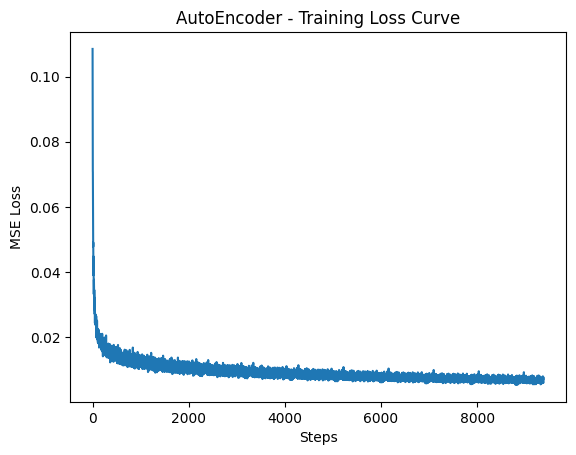

In [19]:
plt.plot(losses)
plt.xlabel("Steps")
plt.ylabel("MSE Loss")
plt.title("AutoEncoder - Training Loss Curve")
plt.show()

이제 평가용 Dataloader를 생성해보자.

In [20]:
eval_bs = 16
eval_dataloader = DataLoader(mnist["train"]["image"], batch_size=eval_bs)

- model.eval()를 사용하여 모델을 평가모드로 설정(BatchNorm 업데이트를 비활성화)
- inference_mode 컨텍스트 관리자를 사용하여 그라디엔트 계산을 비활성화

In [21]:
model.eval()
with torch.inference_mode():
    eval_batch = next(iter(eval_dataloader))
    predicted = model(eval_batch.to(device)).cpu()

이제 예측을 했으니 원본 이미지와 재구성된 이미지를 표시해볼 수 있다

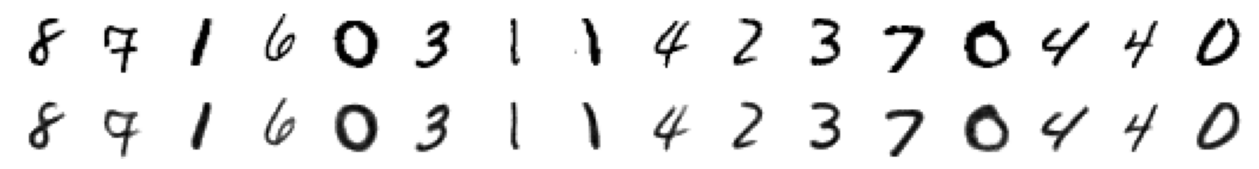

In [22]:
batch_vs_preds = torch.cat((eval_batch, predicted))
show_images(batch_vs_preds, imsize=1, nrows=2)

## 5. 잠재 공간 탐색

잠재공간을 16차원이 아닌 2차원으로 탐색해보자. 이를 위해 리팩토링한 코드는 다음과 같다. 

In [23]:
class Encoder(nn.Module):
    def __init__(self, in_channels, latent_dims):
        super().__init__()
        self.conv_layers = nn.Sequential(
            conv_block(in_channels, 128),
            conv_block(128, 256),
            conv_block(256, 512),
            conv_block(512, 1024),
        )
        self.linear = nn.Linear(1024, latent_dims)
    
    def forward(self, x):
        bs = x.shape[0]
        x = self.conv_layers(x)
        x = self.linear(x.reshape(bs, -1))
        return x

class Decoder(nn.Module):
    def __init__(self, out_channels, latent_dims):
        super().__init__()

        self.linear = nn.Linear(latent_dims, 1024 * 4 * 4)
        self.t_conv_layers = nn.Sequential(
            conv_transpose_block(1024, 512),
            conv_transpose_block(512, 256, output_padding=1),
            conv_transpose_block(
                256, out_channels, output_padding=1, with_act=False
                ),
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        bs = x.shape[0]
        x = self.linear(x)
        x = x.reshape((bs, 1024, 4, 4))
        x = self.t_conv_layers(x)
        x = self.sigmoid(x)
        return x


latent represemtation의 원하는 차원을 지정할 수 있도록 추가 인자인 latent_dims를 받는다. 

In [24]:
class AutoEncoder(nn.Module):
    def __init__(self, in_channels, latent_dims):
        super().__init__()
        self.encoder = Encoder(in_channels, latent_dims)
        self.decoder = Decoder(in_channels, latent_dims)
    
    def encode(self, x):
        return self.encoder(x)
    
    def decode(self, x):
        return self.decoder(x)

    def forward(self, x):
        return self.decode(self.encode(x))

학습 루프는 이전과 동일하지만, 함수를 만들어 재사용하고 필요할 때마다 호출 가능하도록 하였다. 

In [25]:
def train(model, num_epochs=10, lr=1e-4):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, eps=1e-5)
    model.train()
    losses= []
    for _ in (progress:=trange(num_epochs, desc="Training")):
        for _, batch in(
            inner := tqdm(enumerate(train_dataloader), total=len(train_dataloader))
        ):
            batch = batch.to(device)
            preds = model(batch)
            loss = F.mse_loss(preds, batch)
            inner.set_postfix(loss=f"{loss.cpu().item():.3f}")
            losses.append(loss.item())

            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        progress.set_postfix(loss=f"{loss.cpu().item():.3f}", lr=f"{lr:.0e}")
    return losses

두 개의 latent variable을 사용하여 오토인코더를 생성하고 학습한다. 

Training:   0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

...

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

  0%|          | 0/938 [00:00<?, ?it/s]

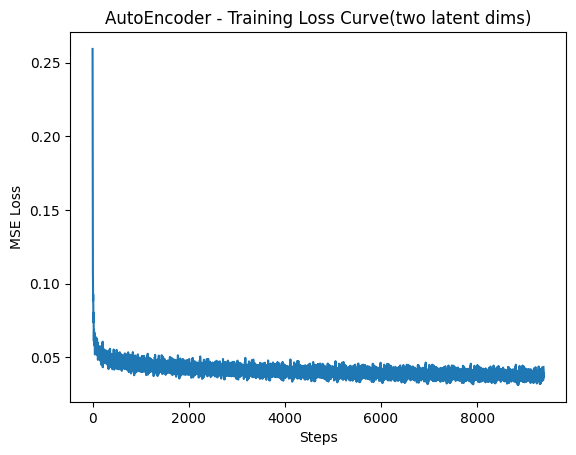

In [26]:
ae_model = AutoEncoder(in_channels=1, latent_dims=2)
ae_model.to(device)
losses = train(ae_model)
plt.plot(losses)
plt.xlabel("Steps")
plt.ylabel("MSE Loss")
plt.title("AutoEncoder - Training Loss Curve(two latent dims)")
plt.show()

다시 한번 학습됨 모델을 불러와서 reconstruction 결과를 살펴보자

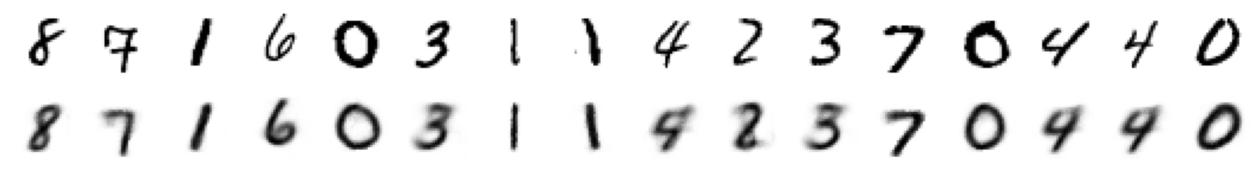

In [27]:
ae_model.eval()
with torch.inference_mode():
    eval_batch = next(iter(eval_dataloader))
    predicted = ae_model(eval_batch.to(device)).cpu()
batch_vs_preds = torch.cat((eval_batch, predicted))
show_images(batch_vs_preds, imsize=1, nrows=2)

## 6. 잠재 공간 시각화

테스트 데이터셋의 모든 인코딩된 벡터를 표현해볼 수 있다. label 열을 사용해 각 클래스에 다른 색을 할당한다. 인코딩된 벡터의 첫 번째 값은 x축에, 두 번쨰 값은 y축에 표시한다. 

  0%|          | 0/20 [00:00<?, ?it/s]

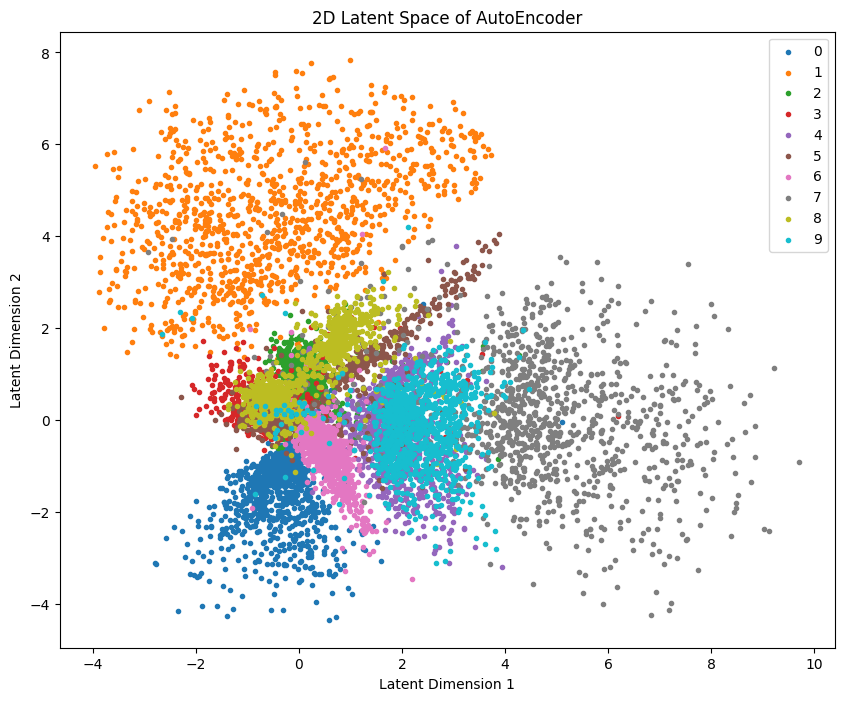

In [28]:
images_labels_dataloader = DataLoader(mnist["test"], batch_size=512)
import pandas as pd

df = pd.DataFrame(
    {
        "x": [],
        "y": [],
        "label": [],
    }
)

for batch in tqdm(
    iter(images_labels_dataloader), total=len(images_labels_dataloader)
):
    encoded = ae_model.encode(batch["image"].to(device)).cpu()
    new_items = {
        "x": [t.item() for t in encoded[:, 0]],
        "y": [t.item() for t in encoded[:, 1]],
        "label": batch["label"],
    }
    df = pd.concat((df, pd.DataFrame(new_items)), ignore_index=True)

plt.figure(figsize=(10, 8))
for label in range(10):
    points = df[df["label"] == label]
    plt.scatter(points["x"], points["y"], label=label, marker=".")
plt.legend()
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("2D Latent Space of AutoEncoder")
plt.show()

- 표현이 차지하는 공간은 모든 방향으로 퍼져있다. 
- 중앙에는 겹침이 있고 큰 공간이 있다. 
- 그래프가 비대칭이다. y 축의 음수값이 양수값보다 더 많이 사용된다. 

좋은 생성물을 만들 수 있는 latent space의 적절한 영역을 선택하기 위해 다음의 과정을 수행해 볼 수 있다. 

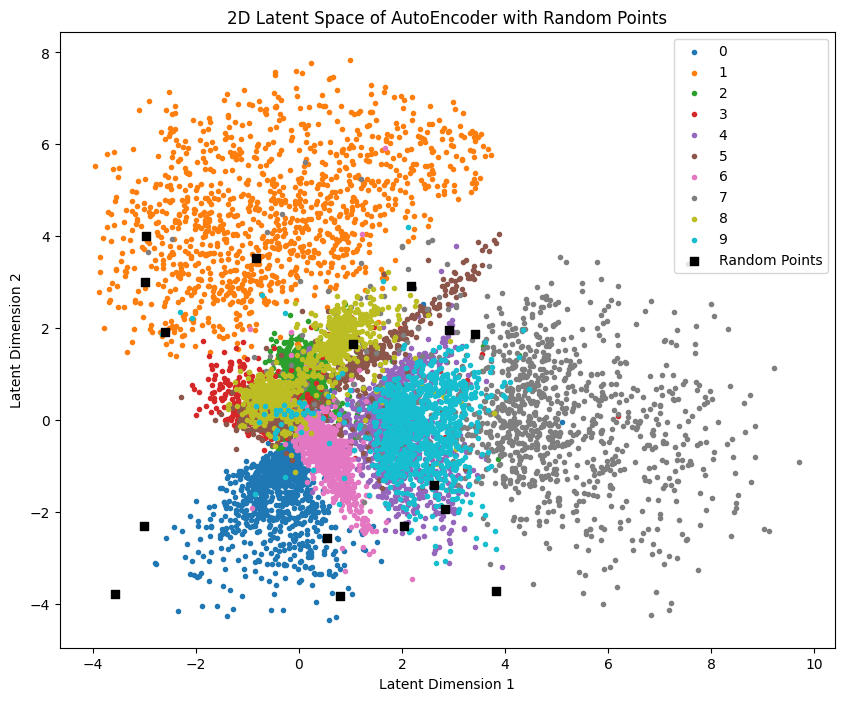

In [29]:
N = 16
z = torch.rand((N, 2)) * 8 - 4

plt.figure(figsize=(10, 8))
for label in range(10):
    points = df[df["label"] == label]
    plt.scatter(points["x"], points["y"], label=label, marker=".")
plt.scatter(z[:, 0], z[:, 1], label="Random Points", marker="s", color="black")
plt.legend()
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("2D Latent Space of AutoEncoder with Random Points")
plt.show()

그리고 방금 만든 latent sample에서 이미지를 생성하도록 디코더에 요청해 볼 수 있다

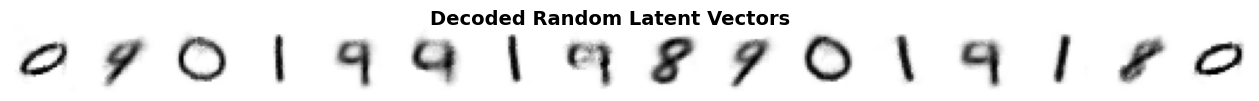

In [30]:
ae_decoded = ae_model.decode(z.to(device))
show_images(ae_decoded.cpu(), imsize=1, nrows=1, title="Decoded Random Latent Vectors")

---

모델 저장

In [31]:
from pathlib import Path

save_dir = Path("chapter03/checkpoints")
save_dir.mkdir(parents=True, exist_ok=True)
ckpt_path = save_dir / "ae_latent2.pth"

torch.save(
    {
        "model_state_dict": ae_model.state_dict(),
        "in_channels": 1,
        "latent_dims": 2,
    },
    ckpt_path,
)
print(f"Saved checkpoint: {ckpt_path.resolve()}")

# from chapter03.checkpoint_loaders import load_autoencoder
# In another notebook:
# ae_model = load_autoencoder(
#     "chapter03/checkpoints/ae_latent2.pth",
#     model_factory=AutoEncoder,
# )


Saved checkpoint: /content/chapter03/checkpoints/ae_latent2.pth
